# 01 · Exploratory analysis and data quality

Loads the raw transaction logs from `data/raw/`, checks completeness and validity against the pre-registered design (`experiments/configs/experiments.json`), and looks at the shape of the latency distributions before any hypothesis testing.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROC, RES = ROOT / "data/raw", ROOT / "data/processed", ROOT / "experiments/results"
LOGS, CONFIG = ROOT / "experiments/logs", ROOT / "experiments/configs/experiments.json"

def load_events(run):
    """One row per logged event (op = one transaction attempt, trial = one trial)."""
    return pd.read_json(RAW / run / "events.jsonl", lines=True)

ORDER = ["naive", "conditional_update", "pessimistic_sorted", "pessimistic_unordered",
         "optimistic_version", "serializable", "advisory_lock"]
COLORS = dict(zip(ORDER, ["#d92d20", "#F84464", "#2e90fa", "#7a5af8", "#12b76a", "#f79009", "#667085"]))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)

In [2]:
neon, lite, live = load_events("main-neon"), load_events("main-pglite"), load_events("main-live")
for name, df in [("main-neon", neon), ("main-pglite", lite), ("main-live", live)]:
    print(f"{name:12s} events={len(df):6d}  by type: {df['type'].value_counts().to_dict()}")

main-neon    events= 12020  by type: {'op': 11280, 'trial': 621, 'cell_start': 39, 'cell_end': 39, 'progress': 39, 'run_start': 1, 'run_end': 1}
main-pglite  events=   443  by type: {'op': 384, 'trial': 48, 'cell_start': 3, 'cell_end': 3, 'progress': 3, 'run_start': 1, 'run_end': 1}
main-live    events=   765  by type: {'op': 738, 'trial': 18, 'cell_start': 3, 'progress': 3, 'run_start': 1, 'cleanup': 1, 'run_end': 1}


## Completeness against the design
Every (experiment, strategy, concurrency) cell must contain exactly the pre-registered number of trials (warm-up trials excluded).

In [3]:
cfg = json.loads(CONFIG.read_text())
trials = neon[(neon.type == "trial") & (~neon.warmup.fillna(False).astype(bool))]
rows = []
for exp in ["E1", "E2", "E3"]:
    e = cfg["experiments"][exp]
    for s in e["strategies"]:
        for c in e["concurrency"]:
            got = len(trials[(trials.exp == exp) & (trials.strategy == s) & (trials.c == c)])
            rows.append((exp, s, c, e["trials"], got))
completeness = pd.DataFrame(rows, columns=["exp", "strategy", "c", "planned", "logged"])
print("cells:", len(completeness), "| incomplete:", (completeness.planned != completeness.logged).sum())
completeness.head(8)

cells: 39 | incomplete: 0


C:\Users\user\AppData\Local\Temp\ipykernel_16968\2879338420.py:2: Pandas4Warning: 'bool' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  trials = neon[(neon.type == "trial") & (~neon.warmup.fillna(False).astype(bool))]


,exp,strategy,c,planned,logged
0,E1,naive,2,20,20
1,E1,naive,8,20,20
2,E1,naive,32,20,20
3,E1,conditional_update,2,20,20
4,E1,conditional_update,8,20,20
5,E1,conditional_update,32,20,20
6,E1,pessimistic_sorted,2,20,20
7,E1,pessimistic_sorted,8,20,20


## Validity checks

In [4]:
ops = neon[(neon.type == "op") & (~neon.warmup.fillna(False).astype(bool))].copy()
checks = {
    "transactions (excl. warm-up)": len(ops),
    "missing latency": int(ops.latencyMs.isna().sum()),
    "negative latency": int((ops.latencyMs < 0).sum()),
    "unexpected errors (outcome == error)": int((ops.outcome == "error").sum()),
    "warm-up trials excluded": int(neon[(neon.type == "trial")].warmup.fillna(False).astype(bool).sum()),
    "duplicate sequence numbers": int(neon.seq.duplicated().sum()),
}
pd.Series(checks)

C:\Users\user\AppData\Local\Temp\ipykernel_16968\4292568689.py:1: Pandas4Warning: 'bool' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  ops = neon[(neon.type == "op") & (~neon.warmup.fillna(False).astype(bool))].copy()


transactions (excl. warm-up)            10380
missing latency                             0
negative latency                            0
unexpected errors (outcome == error)        0
warm-up trials excluded                    39
duplicate sequence numbers                  0
dtype: int64

## Outcomes and latency by experiment

In [5]:
pd.crosstab([ops.exp, ops.strategy], ops.outcome)

outcome                    conflict  deadlock  serialization_failure  success
exp strategy                                                                 
E1  advisory_lock               780         0                      0       60
    conditional_update          780         0                      0       60
    naive                         0         0                      0      840
    optimistic_version          780         0                      0       60
    pessimistic_sorted          780         0                      0       60
    pessimistic_unordered       780         0                      0       60
    serializable                  0         0                    780       60
E2  conditional_update          206         0                      0       34
    naive                         0         0                      0      240
    optimistic_version          204         0                      0       36
    pessimistic_sorted          203         0                      0       37
    pessimistic_unordered       113        93                      0       34
    serializable                  0         0                    225       15
E3  advisory_lock                 0         0                      0      510
    conditional_update            0         0                      0      510
    naive                         0         0                      0      510
    optimistic_version            0         0                      0      510
    pessimistic_sorted            0         0                      0      510
    serializable                  0         0                     24      486

In [6]:
summary = ops.groupby(["exp", "strategy"]).latencyMs.describe(percentiles=[.5, .95])[["count", "50%", "95%", "max"]].round(1)
summary

count     50%     95%     max
exp strategy                                            
E1  advisory_lock          840.0  2213.7  5599.4  6046.3
    conditional_update     840.0  1177.0  2803.1  3050.4
    naive                  840.0  2227.1  5514.7  6127.2
    optimistic_version     840.0  1254.2  2908.1  3176.0
    pessimistic_sorted     840.0  1265.5  2910.2  3209.9
    pessimistic_unordered  840.0  1277.3  2887.3  3123.1
    serializable           840.0   486.4   538.7   810.3
E2  conditional_update     240.0   764.3  1334.4  1457.2
    naive                  240.0  1407.3  2432.1  2990.1
    optimistic_version     240.0   894.3  1462.1  1703.6
    pessimistic_sorted     240.0   921.4  1575.7  2114.9
    pessimistic_unordered  240.0  2889.3  5431.9  6893.6
    serializable           240.0   503.5   544.4   853.7
E3  advisory_lock          510.0  5609.1  5766.2  5829.4
    conditional_update     510.0   346.8   399.8   700.8
    naive                  510.0   431.8   502.0   618.9
    optimistic_version     510.0   444.1   510.0   792.4
    pessimistic_sorted     510.0   439.5   516.8   572.2
    serializable           510.0   438.2   505.7   631.8

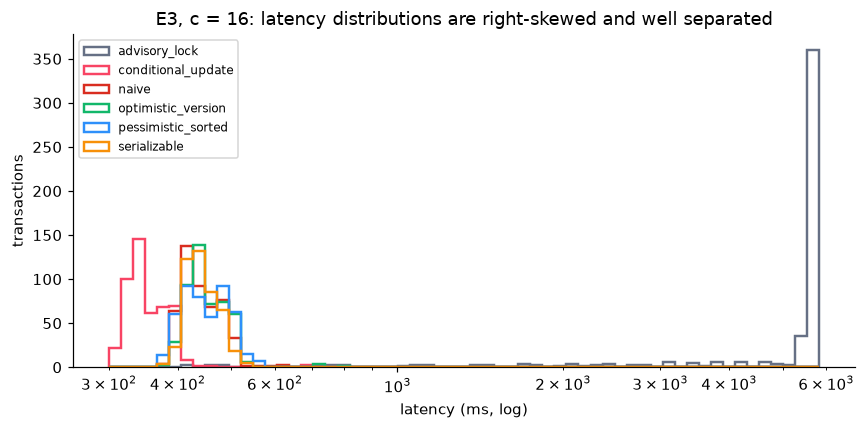

In [7]:
e3 = ops[(ops.exp == "E3") & (ops.c == 16) & (ops.outcome == "success")]
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(np.log10(e3.latencyMs.min()), np.log10(e3.latencyMs.max()), 60)
for s, g in e3.groupby("strategy"):
    ax.hist(g.latencyMs, bins=bins, histtype="step", lw=1.6, label=s, color=COLORS[s])
ax.set_xscale("log"); ax.set_xlabel("latency (ms, log)"); ax.set_ylabel("transactions")
ax.set_title("E3, c = 16: latency distributions are right-skewed and well separated")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

Latencies are right-skewed with long tails, so the analysis uses medians, percentiles and rank-based tests rather than means and t-tests.

## Environment and resource consumption

In [8]:
man = json.loads((LOGS / "main-neon/manifest.json").read_text())
rtt = np.array(man["networkRttMs"]["samples"])
print("git:", man["git"]["sha"][:7], "| node:", man["node"], "| cpu:", man["cpu"], "| RAM GB:", man["memoryGb"])
print("server:", man["server"]["version"][:30], "| pooled:", man["platform"]["pooled"])
print(f"network RTT to DB: median {np.median(rtt):.1f} ms, IQR {np.percentile(rtt,25):.1f}-{np.percentile(rtt,75):.1f} ms")
t = neon[neon.type == "trial"]
print(f"client RSS max {t.rssMb.max():.1f} MB; total trials {len(t)}; run {man['startedAt']} -> {man['finishedAt']}")

git: 47a5505 | node: v24.19.0 | cpu: 12th Gen Intel(R) Core(TM) i5-12400F | RAM GB: 15.9
server: PostgreSQL 18.6 (fd34222) on a | pooled: True
network RTT to DB: median 102.5 ms, IQR 99.4-106.8 ms
client RSS max 67.9 MB; total trials 621; run 2026-10-25T04:51:27.046Z -> 2026-10-25T05:17:55.420Z
